# Transformaciones lineales

Hasta ahora hemos usado las matrices para **resolver sistemas** y para **describir subespacios**. En este cuaderno cambiamos de punto de vista: una matriz es una **función** que toma vectores y devuelve vectores, y las funciones que se comportan bien con la suma y la multiplicación por escalares se llaman **transformaciones lineales**.

Recorremos tres ejemplos de naturaleza muy distinta:

1. **La sucesión de Fibonacci**: una recurrencia que se convierte en potencias de una matriz $2\times2$.
2. **Una transformación $T:\mathbb{R}^3\to\mathbb{R}^2$** dada por una fórmula explícita: su matriz estándar y la solución de $T(x)=\mathbf 0$ (el **núcleo**).
3. **La derivada** $D:P_3\to P_2$: una transformación lineal entre espacios de **polinomios** que también se representa con una matriz.

## 1. La sucesión de Fibonacci con matrices

La sucesión de Fibonacci se define por
$$F_0=0,\qquad F_1=1,\qquad F_{n+1}=F_n+F_{n-1}\quad(n\ge1),$$
de modo que $0,1,1,2,3,5,8,13,21,34,55,\dots$

### 1.1 De la recurrencia a una matriz

Cada término depende de los **dos** anteriores. El truco es guardar dos términos consecutivos en un vector de estado
$$x_n=\begin{pmatrix}F_{n+1}\\F_n\end{pmatrix}\in\mathbb{R}^2 .$$
Pasar de $x_{n-1}$ a $x_n$ es
$$\begin{pmatrix}F_{n+1}\\F_n\end{pmatrix}=\begin{pmatrix}F_n+F_{n-1}\\F_n\end{pmatrix}=\underbrace{\begin{pmatrix}1&1\\1&0\end{pmatrix}}_{A}\begin{pmatrix}F_n\\F_{n-1}\end{pmatrix},
\qquad\text{es decir,}\qquad x_n=A\,x_{n-1}.$$
Aplicando esto una y otra vez desde $x_0=(F_1,F_0)=(1,0)$:
$$x_n=A\,x_{n-1}=A^2x_{n-2}=\dots=\boxed{A^n x_0}.$$

**Calcular Fibonacci = multiplicar matrices.** La función $x\mapsto Ax$ es una transformación lineal de $\mathbb{R}^2$ en $\mathbb{R}^2$; avanzar $n$ pasos en la sucesión es aplicarla $n$ veces, y aplicar una transformación $n$ veces corresponde a la potencia $A^n$.

### 1.2 Las potencias de $A$ contienen la sucesión

Calculemos a mano:
$$A^2=\begin{pmatrix}1&1\\1&0\end{pmatrix}\begin{pmatrix}1&1\\1&0\end{pmatrix}=\begin{pmatrix}2&1\\1&1\end{pmatrix},\qquad
A^3=A^2A=\begin{pmatrix}2&1\\1&1\end{pmatrix}\begin{pmatrix}1&1\\1&0\end{pmatrix}=\begin{pmatrix}3&2\\2&1\end{pmatrix},\qquad
A^4=\begin{pmatrix}5&3\\3&2\end{pmatrix}.$$

Aparecen los números de Fibonacci. En general:

**Teorema.** Para todo $n\ge1$,
$$A^n=\begin{pmatrix}F_{n+1}&F_n\\F_n&F_{n-1}\end{pmatrix}.$$

*Prueba (inducción).* Para $n=1$: $A=\begin{pmatrix}1&1\\1&0\end{pmatrix}=\begin{pmatrix}F_2&F_1\\F_1&F_0\end{pmatrix}$. ✓ Si vale para $n$,
$$A^{n+1}=A^nA=\begin{pmatrix}F_{n+1}&F_n\\F_n&F_{n-1}\end{pmatrix}\begin{pmatrix}1&1\\1&0\end{pmatrix}=\begin{pmatrix}F_{n+1}+F_n&F_{n+1}\\F_n+F_{n-1}&F_n\end{pmatrix}=\begin{pmatrix}F_{n+2}&F_{n+1}\\F_{n+1}&F_n\end{pmatrix}.\qquad\blacksquare$$

**Corolario (identidad de Cassini).** Tomando determinantes, $\det(A^n)=(\det A)^n=(-1)^n$, luego
$$F_{n+1}F_{n-1}-F_n^2=(-1)^n .$$
Por ejemplo, con $n=5$: $F_6F_4-F_5^2=8\cdot3-25=-1$. ✓

### 1.3 Exponenciación rápida: $F_{10}$ con 4 productos

Calcular $A^n$ multiplicando $A$ por sí misma $n-1$ veces no es mejor que usar la recurrencia. La ventaja aparece al **elevar al cuadrado repetidamente**:
$$A^2,\quad A^4=(A^2)^2,\quad A^8=(A^4)^2,\quad A^{16}=(A^8)^2,\ \dots$$
y luego combinar según la escritura de $n$ en binario. Para $n=10=8+2$:
$$A^4=\begin{pmatrix}2&1\\1&1\end{pmatrix}^2=\begin{pmatrix}5&3\\3&2\end{pmatrix},\qquad
A^8=\begin{pmatrix}5&3\\3&2\end{pmatrix}^2=\begin{pmatrix}34&21\\21&13\end{pmatrix},$$
$$A^{10}=A^8A^2=\begin{pmatrix}34&21\\21&13\end{pmatrix}\begin{pmatrix}2&1\\1&1\end{pmatrix}=\begin{pmatrix}89&55\\55&34\end{pmatrix}.$$
Así $F_{10}=55$ (y de paso $F_{11}=89$, $F_9=34$) con **4** productos de matrices en lugar de 9 pasos de la recurrencia.

En general se necesitan del orden de $\log_2 n$ productos: para $n=10^6$ son unos 30 productos frente a un millón de sumas.

> **Adelanto.** Los valores propios de $A$ son las raíces de $\lambda^2-\lambda-1=0$: $\varphi=\frac{1+\sqrt5}2$ (la razón áurea) y $\psi=\frac{1-\sqrt5}2$. Cuando estudiemos **diagonalización** veremos que de $A^n$ sale la fórmula de Binet $F_n=\dfrac{\varphi^n-\psi^n}{\sqrt5}$, y que por eso $F_{n+1}/F_n\to\varphi$.

### 1.4 En Python

Implementamos el producto de matrices $2\times2$ con enteros de Python (que no tienen límite de tamaño) y la exponenciación rápida, y lo comparamos con la recurrencia usual.

In [1]:
def mult2(X, Y):
    """Producto de dos matrices 2x2 dadas como listas de listas."""
    return [[X[0][0] * Y[0][0] + X[0][1] * Y[1][0], X[0][0] * Y[0][1] + X[0][1] * Y[1][1]],
            [X[1][0] * Y[0][0] + X[1][1] * Y[1][0], X[1][0] * Y[0][1] + X[1][1] * Y[1][1]]]


def potencia(A, n):
    """A^n por exponenciación rápida (cuadrados sucesivos)."""
    R = [[1, 0], [0, 1]]  # identidad
    while n > 0:
        if n % 2 == 1:
            R = mult2(R, A)
        A = mult2(A, A)
        n //= 2
    return R


def fib_matriz(n):
    """F_n es la entrada (1,2) de A^n."""
    return potencia([[1, 1], [1, 0]], n)[0][1]


def fib_ciclo(n):
    """F_n con la recurrencia F_{n+1} = F_n + F_{n-1}."""
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a


print("Primeros términos:", [fib_matriz(n) for n in range(15)])
print("A^10 =", potencia([[1, 1], [1, 0]], 10))
print("¿Coinciden los dos métodos para n < 500?", all(fib_matriz(n) == fib_ciclo(n) for n in range(500)))
print("F_100 =", fib_matriz(100))

Primeros términos: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]
A^10 = [[89, 55], [55, 34]]
¿Coinciden los dos métodos para n < 500? True
F_100 = 354224848179261915075


Comparamos tiempos para un $n$ grande. $F_{200\,000}$ tiene más de 40 000 cifras.

In [2]:
import sys
import time

sys.set_int_max_str_digits(0)  # permite convertir a texto enteros de más de 4300 cifras

n = 200_000
t0 = time.perf_counter(); f1 = fib_ciclo(n); t1 = time.perf_counter()
f2 = fib_matriz(n); t2 = time.perf_counter()

print(f"F_{n} tiene {len(str(f1))} cifras; ¿iguales? {f1 == f2}")
print(f"Recurrencia:           {t1 - t0:.4f} s")
print(f"Exponenciación rápida: {t2 - t1:.4f} s")

F_200000 tiene 41798 cifras; ¿iguales? True
Recurrencia:           1.2727 s
Exponenciación rápida: 0.1798 s


**Cuidado con NumPy.** `np.linalg.matrix_power` hace lo mismo, pero con enteros de 64 bits. El mayor número de Fibonacci que cabe es $F_{92}$; a partir de $F_{93}$ el resultado **se desborda** sin avisar.

In [3]:
import numpy as np

A = np.array([[1, 1], [1, 0]])
print("A^10 con NumPy:\n", np.linalg.matrix_power(A, 10))

for n in (92, 93):
    print(f"n = {n}:  NumPy -> {np.linalg.matrix_power(A, n)[0, 1]},   exacto -> {fib_matriz(n)}")

A^10 con NumPy:
 [[89 55]
 [55 34]]
n = 92:  NumPy -> 7540113804746346429,   exacto -> 7540113804746346429
n = 93:  NumPy -> -6246583658587674878,   exacto -> 12200160415121876738


Por último, el cociente $F_{n+1}/F_n$ se acerca rápidamente a la razón áurea $\varphi\approx1.618$, tal como anuncia el adelanto de 1.3.

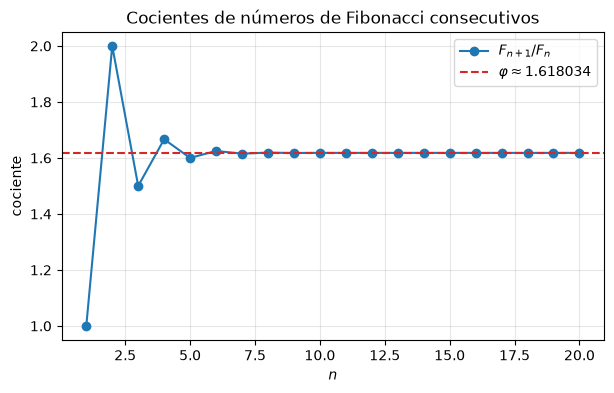

In [4]:
import matplotlib.pyplot as plt

phi = (1 + 5 ** 0.5) / 2
ns = range(1, 21)
cocientes = [fib_matriz(k + 1) / fib_matriz(k) for k in ns]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, cocientes, "o-", label=r"$F_{n+1}/F_n$")
ax.axhline(phi, color="tab:red", linestyle="--", label=rf"$\varphi \approx {phi:.6f}$")
ax.set_xlabel("$n$")
ax.set_ylabel("cociente")
ax.set_title("Cocientes de números de Fibonacci consecutivos")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 2. Transformaciones lineales: definición

**Definición.** Sean $V$ y $W$ espacios vectoriales. Una función $T:V\to W$ es una **transformación lineal** si para todo $u,v\in V$ y todo escalar $c$:
1. $T(u+v)=T(u)+T(v)$,
2. $T(cu)=c\,T(u)$.

Equivalentemente, $T(c_1v_1+\dots+c_kv_k)=c_1T(v_1)+\dots+c_kT(v_k)$: **$T$ respeta combinaciones lineales**.

**Consecuencias inmediatas.**
- $T(\mathbf 0)=\mathbf 0$ (tome $c=0$ en la propiedad 2). Si $T(\mathbf 0)\neq\mathbf 0$, $T$ **no** es lineal.
- $T$ queda **completamente determinada** por lo que hace en una base: si $v=c_1v_1+\dots+c_nv_n$, entonces $T(v)=c_1T(v_1)+\dots+c_nT(v_n)$.

**Las matrices dan transformaciones lineales.** Si $A$ es $m\times n$, la función $T(x)=Ax$ de $\mathbb{R}^n$ en $\mathbb{R}^m$ es lineal, porque $A(u+v)=Au+Av$ y $A(cu)=cAu$. La función $x\mapsto Ax$ de Fibonacci es de este tipo.

**Dos subespacios asociados** (ver la sección 4.2 del [Cuaderno11](Cuaderno11.ipynb)):
$$\ker T=\{v\in V:\ T(v)=\mathbf 0\}\subseteq V\quad(\textbf{núcleo}),\qquad \operatorname{Im}T=\{T(v):\ v\in V\}\subseteq W\quad(\textbf{imagen}),$$
y el teorema rango-nulidad dice $\dim\ker T+\dim\operatorname{Im}T=\dim V$.

## 3. Ejemplo: una transformación de $\mathbb{R}^3$ en $\mathbb{R}^2$

Sea $T:\mathbb{R}^3\to\mathbb{R}^2$ dada por
$$\boxed{T\begin{pmatrix}x_1\\x_2\\x_3\end{pmatrix}=\begin{pmatrix}x_1-x_2+2x_3\\2x_1-x_2+3x_3\end{pmatrix}}.$$

### 3.1 $T$ es lineal

Sean $u=(u_1,u_2,u_3)$, $v=(v_1,v_2,v_3)$ y $c\in\mathbb{R}$. La primera componente de $T(u+v)$ es
$$(u_1+v_1)-(u_2+v_2)+2(u_3+v_3)=(u_1-u_2+2u_3)+(v_1-v_2+2v_3),$$
que es la primera componente de $T(u)+T(v)$; con la segunda componente se razona igual. Análogamente,
$$T(cu)=\begin{pmatrix}cu_1-cu_2+2cu_3\\2cu_1-cu_2+3cu_3\end{pmatrix}=c\begin{pmatrix}u_1-u_2+2u_3\\2u_1-u_2+3u_3\end{pmatrix}=c\,T(u).$$
La clave es que cada componente es una **combinación lineal de $x_1,x_2,x_3$**: sin constantes sumadas, sin productos $x_ix_j$, sin potencias, sin funciones como $\sin x_1$.

**Contraejemplo.** $S(x_1,x_2,x_3)=(x_1+1,\ x_2x_3)$ no es lineal: $S(\mathbf 0)=(1,0)\neq\mathbf 0$.

### 3.2 La matriz estándar

Como $T$ queda determinada por lo que hace en la base canónica $e_1,e_2,e_3$, calculamos
$$T(e_1)=\begin{pmatrix}1\\2\end{pmatrix},\qquad T(e_2)=\begin{pmatrix}-1\\-1\end{pmatrix},\qquad T(e_3)=\begin{pmatrix}2\\3\end{pmatrix},$$
y los ponemos como **columnas**:
$$A=\big[\,T(e_1)\ \ T(e_2)\ \ T(e_3)\,\big]=\begin{pmatrix}1&-1&2\\2&-1&3\end{pmatrix}\qquad(2\times3).$$
Entonces $T(x)=Ax$ para todo $x\in\mathbb{R}^3$, porque
$$T(x)=T(x_1e_1+x_2e_2+x_3e_3)=x_1T(e_1)+x_2T(e_2)+x_3T(e_3)=Ax .$$
Observe que los **coeficientes de la fórmula** son exactamente las **filas** de $A$.

**Evaluación.** Para $x=(1,2,3)$:
$$T(1,2,3)=\begin{pmatrix}1-2+6\\2-2+9\end{pmatrix}=\begin{pmatrix}5\\9\end{pmatrix},\qquad
\begin{pmatrix}1&-1&2\\2&-1&3\end{pmatrix}\begin{pmatrix}1\\2\\3\end{pmatrix}=\begin{pmatrix}5\\9\end{pmatrix}.\ ✓$$

### 3.3 Resolver $T(x)=\mathbf 0$: el núcleo de $T$

$T(x)=\mathbf 0$ es el sistema homogéneo $Ax=\mathbf 0$:
$$\begin{cases}x_1-x_2+2x_3=0\\2x_1-x_2+3x_3=0\end{cases}$$
Reducimos:
$$\begin{pmatrix}1&-1&2\\2&-1&3\end{pmatrix}\xrightarrow{F_2-2F_1}\begin{pmatrix}1&-1&2\\0&1&-1\end{pmatrix}\xrightarrow{F_1+F_2}\begin{pmatrix}\boxed1&0&1\\0&\boxed1&-1\end{pmatrix}.$$
Pivotes en las columnas 1 y 2; $x_3$ es libre. De $x_1+x_3=0$ y $x_2-x_3=0$:
$$x=\begin{pmatrix}-x_3\\x_3\\x_3\end{pmatrix}=x_3\begin{pmatrix}-1\\1\\1\end{pmatrix},\qquad
\boxed{\ker T=\operatorname{gen}\left\{\begin{pmatrix}-1\\1\\1\end{pmatrix}\right\}}.$$
Comprobación: $T(-1,1,1)=(-1-1+2,\ -2-1+3)=(0,0)$. ✓

**Interpretación.**
- $\ker T$ es una **recta por el origen** en $\mathbb{R}^3$: todos sus puntos se aplastan en el $\mathbf 0$ de $\mathbb{R}^2$.
- $\dim\ker T=1$, así que por rango-nulidad $\dim\operatorname{Im}T=3-1=2$: la imagen es **todo** $\mathbb{R}^2$. $T$ es **sobreyectiva**.
- Como $\ker T\neq\{\mathbf 0\}$, $T$ **no es inyectiva**: por ejemplo $T(0,0,0)=T(-1,1,1)$.

**Relación con $T(x)=b$.** Vimos que $T(1,2,3)=(5,9)$. Por la sección 5.2 del Cuaderno11, **todas** las soluciones de $T(x)=(5,9)$ son
$$x=\begin{pmatrix}1\\2\\3\end{pmatrix}+t\begin{pmatrix}-1\\1\\1\end{pmatrix},\qquad t\in\mathbb{R}:$$
la recta $\ker T$ trasladada. Por ejemplo, con $t=3$: $T(-2,5,6)=(-2-5+12,\ -4-5+18)=(5,9)$. ✓

### 3.4 Verificación con SymPy

In [5]:
import sympy as sp
from IPython.display import display

x1, x2, x3 = sp.symbols("x1 x2 x3")


def T(v):
    a, b, c = v
    return sp.Matrix([a - b + 2 * c, 2 * a - b + 3 * c])


# Matriz estándar: columnas T(e1), T(e2), T(e3)
A = sp.Matrix.hstack(T([1, 0, 0]), T([0, 1, 0]), T([0, 0, 1]))
print("Matriz estándar A:")
display(A)

print("T(1,2,3) con la fórmula y con la matriz:")
display(T([1, 2, 3]), A * sp.Matrix([1, 2, 3]))

print("Forma escalonada reducida y columnas pivote:")
display(A.rref())

print("Base de ker T:")
display(A.nullspace())

print("Solución de T(x) = 0 y de T(x) = (5, 9):")
display(sp.linsolve((A, sp.Matrix([0, 0])), x1, x2, x3))
display(sp.linsolve((A, sp.Matrix([5, 9])), x1, x2, x3))

Matriz estándar A:


Matrix([
[1, -1, 2],
[2, -1, 3]])

T(1,2,3) con la fórmula y con la matriz:


Matrix([
[5],
[9]])

Matrix([
[5],
[9]])

Forma escalonada reducida y columnas pivote:


... (2 outputs left out)

[Matrix([
 [-1],
 [ 1],
 [ 1]])]

Solución de T(x) = 0 y de T(x) = (5, 9):


{(-x3, x3, x3)}

{(4 - x3, x3 - 1, x3)}

SymPy expresa las soluciones en términos de la variable libre $x_3$: $(-x_3,\,x_3,\,x_3)$ para $T(x)=\mathbf 0$ y $(4-x_3,\,-1+x_3,\,x_3)$ para $T(x)=(5,9)$. Es la misma recta de 3.3 escrita con otro parámetro: con $x_3=3$ se obtiene $(1,2,3)$ y con $x_3=6$ se obtiene $(-2,5,6)$.

## 4. Ejemplo: la derivada entre espacios de polinomios

Sea $P_n$ el espacio de polinomios de grado $\le n$, y
$$D:P_3\to P_2,\qquad D(p)=p' .$$

### 4.1 $D$ es lineal

Son las reglas de derivación que ya conoce:
$$(p+q)'=p'+q',\qquad (cp)'=c\,p' .$$
Por ejemplo, $D(2-x+4x^2+5x^3)=-1+8x+15x^2$.

### 4.2 La matriz de $D$

Usamos las bases $\mathcal B=\{1,x,x^2,x^3\}$ de $P_3$ y $\mathcal C=\{1,x,x^2\}$ de $P_2$. Igual que en 3.2, las columnas de la matriz son las **coordenadas** de las imágenes de la base:
$$D(1)=0,\qquad D(x)=1,\qquad D(x^2)=2x,\qquad D(x^3)=3x^2,$$
$$[D]_{\mathcal C\leftarrow\mathcal B}=\Big[\,[D(1)]_{\mathcal C}\ \ [D(x)]_{\mathcal C}\ \ [D(x^2)]_{\mathcal C}\ \ [D(x^3)]_{\mathcal C}\,\Big]=\begin{pmatrix}0&1&0&0\\0&0&2&0\\0&0&0&3\end{pmatrix}\qquad(3\times4).$$

Esta matriz cumple
$$[D(p)]_{\mathcal C}=[D]_{\mathcal C\leftarrow\mathcal B}\,[p]_{\mathcal B}:$$
**derivar es multiplicar la matriz por el vector de coeficientes**. Con $p=2-x+4x^2+5x^3$, $[p]_{\mathcal B}=(2,-1,4,5)$:
$$\begin{pmatrix}0&1&0&0\\0&0&2&0\\0&0&0&3\end{pmatrix}\begin{pmatrix}2\\-1\\4\\5\end{pmatrix}=\begin{pmatrix}-1\\8\\15\end{pmatrix}\quad\longleftrightarrow\quad -1+8x+15x^2 .\ ✓$$

### 4.3 Núcleo e imagen de $D$

- **$D(p)=0$:** la matriz ya está escalonada con pivotes en las columnas 2, 3 y 4; la única variable libre es $a_0$. Luego $\operatorname{Nul}[D]=\operatorname{gen}\{(1,0,0,0)\}$, es decir,
$$\ker D=\operatorname{gen}\{1\}=\{\text{polinomios constantes}\}.$$
Es el hecho conocido: *la derivada es cero exactamente para las constantes*.
- **Imagen:** hay 3 pivotes, así que $\dim\operatorname{Im}D=3=\dim P_2$: $\operatorname{Im}D=P_2$ (todo polinomio de grado $\le2$ es la derivada de alguno).
- **Rango-nulidad:** $1+3=4=\dim P_3$. ✓

### 4.4 Resolver $D(p)=q$: las antiderivadas

Busquemos $p\in P_3$ con $p'=q=3+2x-6x^2$. En coordenadas, $[D]\,(a_0,a_1,a_2,a_3)^T=(3,2,-6)^T$:
$$a_1=3,\qquad 2a_2=2\Rightarrow a_2=1,\qquad 3a_3=-6\Rightarrow a_3=-2,\qquad a_0\ \text{libre}.$$
$$p=\underbrace{3x+x^2-2x^3}_{\text{solución particular}}+\underbrace{a_0}_{\in\,\ker D}.$$
La **constante de integración** $+C$ del cálculo es exactamente el núcleo de $D$: la misma estructura "solución particular $+$ núcleo" que en 3.3.

### 4.5 Composición = producto de matrices

Si tomamos $D:P_3\to P_3$ (misma base $\mathcal B$ en la salida y la llegada), la matriz es cuadrada:
$$N=\begin{pmatrix}0&1&0&0\\0&0&2&0\\0&0&0&3\\0&0&0&0\end{pmatrix}.$$
Derivar dos veces es aplicar $D\circ D$, cuya matriz es $N^2$:
$$N^2=\begin{pmatrix}0&0&2&0\\0&0&0&6\\0&0&0&0\\0&0&0&0\end{pmatrix}\qquad\big(D^2(x^2)=2,\ D^2(x^3)=6x\big),$$
y como la cuarta derivada de un polinomio de grado $\le3$ es cero, $N^4=O$ aunque $N\neq O$ (una matriz **nilpotente**). Igual que con Fibonacci: **aplicar una transformación $k$ veces = elevar su matriz a la $k$**.

### 4.6 Verificación con SymPy

In [6]:
x = sp.symbols("x")
base_P3 = [sp.Integer(1), x, x**2, x**3]


def coordenadas(p, grado):
    """Vector de coeficientes de p en la base {1, x, ..., x^grado}."""
    p = sp.Poly(p, x)
    return sp.Matrix([p.coeff_monomial(x**k) for k in range(grado + 1)])


# Columnas: coordenadas de D(1), D(x), D(x^2), D(x^3) en {1, x, x^2}
D = sp.Matrix.hstack(*[coordenadas(sp.diff(b, x), 2) for b in base_P3])
print("Matriz de D: P3 -> P2")
display(D)

p = 2 - x + 4 * x**2 + 5 * x**3
print("[D][p] y coordenadas de p' calculada con sp.diff:")
display(D * coordenadas(p, 3), coordenadas(sp.diff(p, x), 2))

print("Base de ker D (en coordenadas):")
display(D.nullspace())

a0, a1, a2, a3 = sp.symbols("a0:4")
print("Soluciones de D(p) = 3 + 2x - 6x^2:")
display(sp.linsolve((D, coordenadas(3 + 2 * x - 6 * x**2, 2)), a0, a1, a2, a3))

# D: P3 -> P3 y sus potencias
N = sp.Matrix.hstack(*[coordenadas(sp.diff(b, x), 3) for b in base_P3])
print("N, N^2 y N^4:")
display(N, N**2, N**4)

Matriz de D: P3 -> P2


Matrix([
[0, 1, 0, 0],
[0, 0, 2, 0],
[0, 0, 0, 3]])

[D][p] y coordenadas de p' calculada con sp.diff:


Matrix([
[-1],
[ 8],
[15]])

Matrix([
[-1],
[ 8],
[15]])

Base de ker D (en coordenadas):


... (3 outputs left out)

N, N^2 y N^4:


Matrix([
[0, 1, 0, 0],
[0, 0, 2, 0],
[0, 0, 0, 3],
[0, 0, 0, 0]])

Matrix([
[0, 0, 2, 0],
[0, 0, 0, 6],
[0, 0, 0, 0],
[0, 0, 0, 0]])

Matrix([
[0, 0, 0, 0],
[0, 0, 0, 0],
[0, 0, 0, 0],
[0, 0, 0, 0]])

## 5. Resumen

- $T:V\to W$ es **lineal** si $T(u+v)=T(u)+T(v)$ y $T(cu)=cT(u)$. En particular $T(\mathbf 0)=\mathbf 0$, y $T$ queda determinada por las imágenes de una base.
- Toda $T:\mathbb{R}^n\to\mathbb{R}^m$ lineal es $T(x)=Ax$ con la **matriz estándar** $A=[\,T(e_1)\ \cdots\ T(e_n)\,]$. Con una fórmula explícita, los coeficientes de cada componente son las filas de $A$.
- Entre espacios abstractos (como $P_3\to P_2$), las columnas de la matriz son las **coordenadas** de las imágenes de la base: $[T(v)]_{\mathcal C}=[T]_{\mathcal C\leftarrow\mathcal B}[v]_{\mathcal B}$.
- **Núcleo:** $\ker T$ es la solución de $T(x)=\mathbf 0$, es decir $\operatorname{Nul}(A)$. Las soluciones de $T(x)=b$ son una solución particular más $\ker T$. $T$ es inyectiva $\iff\ker T=\{\mathbf 0\}$.
- **Composición = producto de matrices.** Aplicar $T$ $k$ veces corresponde a $A^k$: así se calcula Fibonacci ($x_n=A^nx_0$, con $A^n=\begin{pmatrix}F_{n+1}&F_n\\F_n&F_{n-1}\end{pmatrix}$) y así se derivan polinomios varias veces ($N^k$).

## 6. Ejercicios

### A. Fibonacci y potencias

1. Calcule a mano $A^{16}$ por cuadrados sucesivos y lea $F_{15}$, $F_{16}$ y $F_{17}$. ¿Cuántos productos usó para $A^{20}$?
2. Usando $A^{m+n}=A^mA^n$, demuestre que $F_{m+n}=F_{m+1}F_n+F_mF_{n-1}$. Deduzca $F_{2n}=F_n(F_{n+1}+F_{n-1})$.
3. La sucesión de Lucas cumple la misma recurrencia con $L_0=2$, $L_1=1$. Escriba $(L_{n+1},L_n)$ como $A^n$ por un vector y calcule $L_{10}$.
4. Encuentre una matriz $3\times3$ que calcule la sucesión de **Tribonacci** $T_{n+1}=T_n+T_{n-1}+T_{n-2}$.

### B. Transformaciones de $\mathbb{R}^n$ en $\mathbb{R}^m$

5. Decida si son lineales; si lo son, halle su matriz estándar: (a) $T(x,y,z)=(x+z,\ 3y)$; (b) $T(x,y)=(x+y,\ 1)$; (c) $T(x,y,z)=(xy,\ z)$; (d) $T(x,y)=(2x-y,\ x,\ 0)$.
6. Para $T(x_1,x_2,x_3)=(x_1+2x_2-x_3,\ 2x_1+4x_2-2x_3)$, resuelva $T(x)=\mathbf 0$, describa $\ker T$ geométricamente y halle $\dim\operatorname{Im}T$. ¿Es $T$ sobreyectiva?
7. Sea $T:\mathbb{R}^3\to\mathbb{R}^2$ lineal con $T(1,0,0)=(2,1)$, $T(0,1,0)=(0,-1)$, $T(0,0,1)=(1,1)$. Halle $T(3,-2,4)$ y $\ker T$.
8. Demuestre que una transformación lineal $T:\mathbb{R}^3\to\mathbb{R}^2$ **nunca** es inyectiva.

### C. Polinomios

9. Halle la matriz de $D:P_4\to P_3$ en las bases canónicas, y la de $D^2:P_4\to P_2$. Compruebe que la segunda es el producto de la matriz de $D:P_3\to P_2$ por la de $D:P_4\to P_3$.
10. Sea $J:P_2\to P_3$, $J(p)=\int_0^x p(t)\,dt$. Halle su matriz, $\ker J$ y verifique que $[D][J]=I_3$. ¿Es $[J][D]=I_4$? Interprete.
11. Sea $T:P_2\to P_2$, $T(p)=p+xp'$. Halle su matriz en $\{1,x,x^2\}$ y resuelva $T(p)=1+2x+9x^2$.